# WIA3003: Academic Project II
## Train-Test Split Ratio Experiment

This experiment checks how the train-test ratio and the random choice of test records affect the reported score. It does not search for the split with the highest score. Choosing a split by its test result would bias every later comparison.

Each ratio is repeated with 30 random splits. Records with identical measurements stay on the same side, and each split keeps the male/female proportion. Logistic regression and XGBoost are used because they train quickly. Claude assisted with writing and running this notebook.

## 1.0 Load Dataset

Use the same workbook, features and label mapping as the earlier notebooks.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

folder = Path.cwd()
project_folder = folder.parent if folder.name == "notebooks" else folder
details = json.loads((project_folder / "results" / "qcnn_baseline" / "run_details.json").read_text(encoding="utf-8"))

data_path = Path.home() / "Downloads" / "Orbital, Nasal and Craniofacial Class Pattern.xls"
dataset_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
if dataset_hash != details["dataset_sha256"]:
    raise ValueError("Workbook changed since the grouped QCNN run. Verify the data first.")

df = pd.read_excel(data_path, sheet_name="Raw Data")
df.columns = df.columns.str.replace(r"\s+", " ", regex=True).str.strip()
features = details["features"]
X = df[features].apply(pd.to_numeric, errors="raise")
y = df["Gender"].astype("string").str.strip().map(details["label_mapping"]).astype(int)

groups = X.groupby(features, sort=False, dropna=False).ngroup().to_numpy()
group_labels = pd.Series(y.to_numpy()).groupby(groups).agg(["min", "max", "size"])
print("Records:", len(X), "Groups:", len(group_labels))
print("Groups with more than one record:", int((group_labels["size"] > 1).sum()))
print("Groups with both sexes:", int((group_labels["min"] != group_labels["max"]).sum()))

Records: 1042 Groups: 1037
Groups with more than one record: 5
Groups with both sexes: 4


## 2.0 Settings

Fix the ratios, seeds and model settings before running. Model settings match notebooks 02 and 07. The split is drawn at group level, stratified by sex, then mapped back to records.

In [2]:
TEST_SIZES = [0.10, 0.20, 0.30, 0.40]
REPEATS = 30
SPLIT_SEED = 42

def make_models():
    return {
        "Logistic regression": Pipeline([
            ("scaler", StandardScaler()),
            ("logistic", LogisticRegression(solver="lbfgs", C=1.0, max_iter=1000)),
        ]),
        "XGBoost": XGBClassifier(
            objective="binary:logistic", eval_metric="logloss", n_estimators=100,
            max_depth=3, learning_rate=0.1, tree_method="hist", random_state=42, n_jobs=1,
        ),
    }

# A group with both sexes cannot be stratified by one label; use its first record.
group_ids = group_labels.index.to_numpy()
strata = pd.Series(y.to_numpy()).groupby(groups).first().to_numpy()

def grouped_splits(test_size):
    splitter = StratifiedShuffleSplit(n_splits=REPEATS, test_size=test_size, random_state=SPLIT_SEED)
    for repeat, (train_groups, test_groups) in enumerate(splitter.split(group_ids, strata)):
        test_mask = np.isin(groups, group_ids[test_groups])
        yield repeat, np.flatnonzero(~test_mask), np.flatnonzero(test_mask)

## 3.0 Run Repeated Splits

In [3]:
rows = []
for test_size in TEST_SIZES:
    for repeat, train_rows, test_rows in grouped_splits(test_size):
        assert not set(groups[train_rows]) & set(groups[test_rows])
        for name, model in make_models().items():
            model.fit(X.iloc[train_rows], y.iloc[train_rows])
            predictions = model.predict(X.iloc[test_rows])
            rows.append({
                "Split": f"{round((1 - test_size) * 100)}:{round(test_size * 100)}",
                "Repeat": repeat, "Model": name,
                "Training records": len(train_rows), "Test records": len(test_rows),
                "Test male share": y.iloc[test_rows].mean(),
                "Accuracy": accuracy_score(y.iloc[test_rows], predictions),
                "Macro F1": f1_score(y.iloc[test_rows], predictions, average="macro"),
            })
runs = pd.DataFrame(rows)
print("Model fits completed:", len(runs))

Model fits completed: 240


## 4.0 Compare Ratios

The standard deviation shows how much one randomly chosen split can move the score. Minimum and maximum show the range a single split could have reported.

In [4]:
order = [f"{round((1 - size) * 100)}:{round(size * 100)}" for size in TEST_SIZES][::-1]
summary = (runs.groupby(["Model", "Split"])
    .agg(**{
        "Test records": ("Test records", "mean"),
        "Macro F1 mean": ("Macro F1", "mean"), "Macro F1 std": ("Macro F1", "std"),
        "Macro F1 min": ("Macro F1", "min"), "Macro F1 max": ("Macro F1", "max"),
        "Accuracy mean": ("Accuracy", "mean"), "Accuracy std": ("Accuracy", "std"),
    })
    .reindex(order, level="Split"))
display(summary.round(4))

Test records  Macro F1 mean  Macro F1 std  \
Model               Split                                              
Logistic regression 60:40      416.7333         0.7605        0.0164   
                    70:30      313.0667         0.7620        0.0232   
                    80:20      209.0667         0.7592        0.0306   
                    90:10      104.6000         0.7596        0.0388   
XGBoost             60:40      416.7333         0.7457        0.0150   
                    70:30      313.0667         0.7492        0.0233   
                    80:20      209.0667         0.7521        0.0302   
                    90:10      104.6000         0.7550        0.0331   

                           Macro F1 min  Macro F1 max  Accuracy mean  \
Model               Split                                              
Logistic regression 60:40        0.7260        0.7951         0.7650   
                    70:30        0.7114        0.8135         0.7663   
                    80:20        0.7022        0.8197         0.7639   
                    90:10        0.6630        0.8259         0.7646   
XGBoost             60:40        0.7179        0.7724         0.7508   
                    70:30        0.7088        0.8073         0.7540   
                    80:20        0.6900        0.8070         0.7569   
                    90:10        0.6905        0.8158         0.7597   

                           Accuracy std  
Model               Split                
Logistic regression 60:40        0.0162  
                    70:30        0.0227  
                    80:20        0.0302  
                    90:10        0.0372  
XGBoost             60:40        0.0145  
                    70:30        0.0229  
                    80:20        0.0296  
                    90:10        0.0318

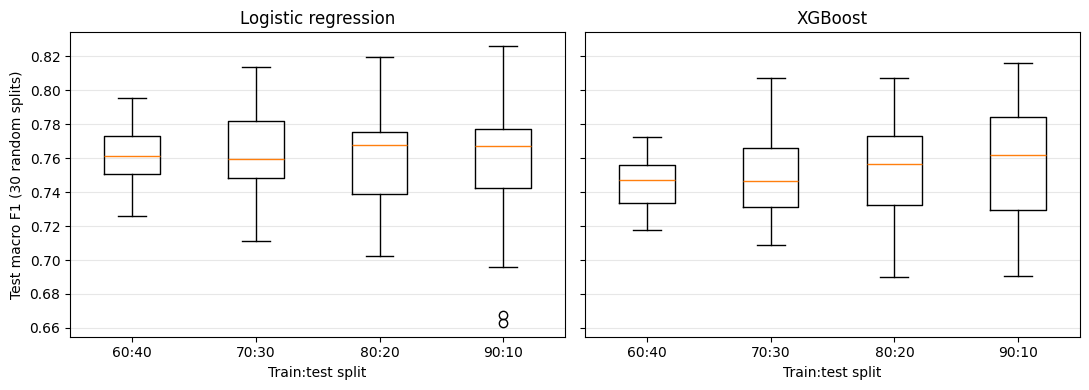

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, frame) in zip(axes, runs.groupby("Model")):
    ax.boxplot([frame.loc[frame["Split"] == split, "Macro F1"] for split in order], tick_labels=order)
    ax.set_title(name)
    ax.set_xlabel("Train:test split")
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Test macro F1 (30 random splits)")
fig.tight_layout()

output_folder = project_folder / "results" / "split_ratio_experiment"
output_folder.mkdir(parents=True, exist_ok=True)
fig.savefig(output_folder / "macro_f1_by_split.png", dpi=200, bbox_inches="tight")
plt.show()

## 5.0 Position of the Saved Split

Compare the single grouped 80:20 split used in notebooks 03 to 11 with the 30 random 80:20 splits. This shows whether the saved split is typical.

In [6]:
saved = {
    "Logistic regression": pd.read_csv(project_folder / "results" / "logistic_regression_baseline" / "metrics.csv")["Macro F1"].iloc[0],
    "XGBoost": pd.read_csv(project_folder / "results" / "grouped_baselines" / "model_comparison.csv", index_col="Model").loc["XGBoost", "Macro F1"],
}
position = []
for name, value in saved.items():
    scores = runs.loc[(runs["Model"] == name) & (runs["Split"] == "80:20"), "Macro F1"]
    position.append({
        "Model": name, "Saved split macro F1": value,
        "Random 80:20 mean": scores.mean(), "Random 80:20 std": scores.std(),
        "Random splits below saved": int((scores < value).sum()), "Random splits": len(scores),
    })
position = pd.DataFrame(position).set_index("Model")
display(position.round(4))

,Saved split macro F1,Random 80:20 mean,Random 80:20 std,Random splits below saved,Random splits
Model,,,,,
Logistic regression,0.7998,0.7592,0.0306,27,30
XGBoost,0.7841,0.7521,0.0302,25,30


## 6.0 Save Results

In [7]:
runs.to_csv(output_folder / "split_runs.csv", index=False)
summary.to_csv(output_folder / "split_summary.csv")
position.to_csv(output_folder / "saved_split_position.csv")
settings = {
    "dataset_sha256": dataset_hash, "features": features,
    "test_sizes": TEST_SIZES, "repeats": REPEATS, "split_seed": SPLIT_SEED,
    "method": "StratifiedShuffleSplit on groups of identical measurements",
    "sklearn_version": sklearn.__version__, "xgboost_version": xgboost.__version__,
}
(output_folder / "settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
print("Saved results to:", output_folder)

Saved results to: C:\Users\jwenn\Desktop\UM\FYP\FYP-Project\results\split_ratio_experiment
